In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

def cm_to_inches(cm_tuple):
    return tuple(x / 2.54 for x in cm_tuple)

def setup_plotting_environment():
    plt.rcParams.update({'font.size': 6, 'font.family': 'Helvetica'})

setup_plotting_environment()

plot_folder = 'plots/DEG_analysis'
os.makedirs(plot_folder, exist_ok=True)

In [2]:
import sys
sys.path.append('..')
from constants import CELL_TYPE_COLORS, ALL_CELL_TYPES
ALL_CELL_TYPES_EXCLUDE = [cell for cell in ALL_CELL_TYPES if cell not in ["ILC", "pDC"]]

# info on cytokines
cytokine_info = pd.read_excel("../../annotations/20250405_cytokine_info_with_functional_classification_LO.xlsx", index_col=0, sheet_name="all_cytokines")
cytokine_info["single_gene"] = cytokine_info["gene"].str.split(",").str[0]

cytokine_info_parse = cytokine_info[cytokine_info["parse_cytokine"]]
cytokine_info_order = pd.read_excel("../../annotations/20250405_cytokine_info_with_functional_classification_LO.xlsx", index_col=0, sheet_name="suggested_order")

CYTOKINE_ORDER = list(cytokine_info_order["name"])

FileNotFoundError: [Errno 2] No such file or directory: '../../annotations/20250405_cytokine_info_with_functional_classification_LO.xlsx'

In [ ]:
alt_flag = False
wells = ["H7", "H8", "H9", "H10", "H11", "H12"]

if not alt_flag:
    relevant_cell_types = [
        "CD4",
        "CD8",
        "B",
        "CD56-bright_NK",
        "Treg",
        "MAIT",
        "CD14_Mono",
        "CD16_Mono",
        "CD56-dim_NK",
        "NKT",
        "cDC",
        "pDC",
        "other",
        "ILC",
        "HSPC",
    ]
    relevant_cell_type_conversion = {
        "B": "B cell",
        "CD4": "CD4 T cell",
        "CD8": "CD8 T cell",
        "Treg": "Treg",
        "MAIT": "MAIT",
        "NKT": "NKT",
        "cDC": "cDC",
        "pDC": "pDC",
        "CD56-bright_NK": "NK CD56hi",
        "CD56-dim_NK": "NK CD56low",
        "CD14_Mono": "CD14 Mono",
        "CD16_Mono": "CD16 Mono",
        "HSPC": "HSPC",
        "other": "granulocyte",
        "ILC": "ILC",
    }
else:
    relevant_cell_types = [
        "CD4_Naive",
        "CD4_Memory",
        "CD8_Naive",
        "CD8_Memory",
        "B_Naive",
        "B_Intermediate_Memory",
        "Treg",
        "MAIT",
        "CD14_Mono",
        "CD16_Mono",
        "CD56-bright_NK",
        "CD56-dim_NK",
        "NKT",
        "cDC",
        "pDC",
        "other",
        "ILC",
        "HSPC",
    ]
    relevant_cell_type_conversion = {
        "CD4_Naive": "CD4 Naive",
        "CD4_Memory": "CD4 Memory",
        "CD8_Naive": "CD8 Naive",
        "CD8_Memory": "CD8 Memory",
        "B_Naive": "B Naive",
        "B_Intermediate_Memory": "B Intermediate",
        "B_Intermediate": "B Intermediate",
        "Treg": "Treg",
        "MAIT": "MAIT",
        "NKT": "NKT",
        "cDC": "cDC",
        "pDC": "pDC",
        "CD56-bright_NK": "NK CD56hi",
        "CD56-dim_NK": "NK CD56low",
        "CD14_Mono": "CD14 Mono",
        "CD16_Mono": "CD16 Mono",
        "HSPC": "HSPC",
        "other": "granulocyte",
        "ILC": "ILC",
    }

#### Load original DEGs

In [ ]:
def create_edger_val_df(result_df, val_type):
    """
    Creates a DataFrame from EdgeR results with a MultiIndex of (cell_type, cytokine) columns.
    
    Parameters:
    -----------
    result_df : pandas.DataFrame
        The EdgeR results DataFrame containing gene, cell_type, cytokine, and value columns.
    val_type : str
        The column name in result_df to use as values (e.g., 'adj_p_value', 'log_fc', 'logCPM').
        
    Returns:
    --------
    pandas.DataFrame
        A pivoted DataFrame with genes as index and MultiIndex columns of (cell_type, cytokine),
        containing the specified values. Missing combinations are filled with NaN.
    """
    # rename 
    df = result_df[[val_type, "gene", "cell_type", "cytokine"]]
    # reformat to columns = (cell_type, cytokine)
    df = df.pivot(index="gene",columns=["cell_type", "cytokine"], values=val_type)
    # create tuples of (cell_type, cytokine) for all combinations
    column_tuples = [(cell_type, cytokine) 
                    for cell_type in relevant_cell_type_conversion.values() 
                    for cytokine in CYTOKINE_ORDER]
    df = df.reindex(pd.MultiIndex.from_tuples(column_tuples), axis=1)
    return df


# basically a concatenated table of all DEGs
edger_results = pd.read_csv(os.path.join("../../../data/", "DEGs_all_with_pbs_DE_count.csv"), index_col=0)
edger_results = edger_results.rename(columns={"celltype": "cell_type"})

edger_results = edger_results[edger_results["cell_type"].isin(relevant_cell_type_conversion.keys())]
edger_results["cell_type"] = edger_results["cell_type"].map(relevant_cell_type_conversion)

In [ ]:
edger_df_padj = create_edger_val_df(edger_results, "adj_p_value")
edger_df_log2CPM = create_edger_val_df(edger_results, "logCPM")
edger_df_log2FoldChange = create_edger_val_df(edger_results, "log_fc")

#### Load per-well DEGs

In [ ]:
# Need data vs separate PBS wells for more varied cell types

In [ ]:
input_data_folder = "../../data/DEG_vs_separate_PBS"
files = os.listdir(input_data_folder)

In [10]:
def create_edger_val_df_with_wells(result_df, val_type):
    """
    Creates a DataFrame from EdgeR results with a MultiIndex of (cell_type, cytokine) columns.
    
    Parameters:
    -----------
    result_df : pandas.DataFrame
        The EdgeR results DataFrame containing gene, cell_type, cytokine, and value columns.
    val_type : str
        The column name in result_df to use as values (e.g., 'adj_p_value', 'log_fc', 'logCPM').
        
    Returns:
    --------
    pandas.DataFrame
        A pivoted DataFrame with genes as index and MultiIndex columns of (cell_type, cytokine),
        containing the specified values. Missing combinations are filled with NaN.
    """
    # rename 
    df = result_df[[val_type, "gene", "cell_type", "cytokine", "pbs_well"]]
    # reformat to columns = (cell_type, cytokine, well)
    df = df.pivot(index="gene",columns=["cell_type", "cytokine", "pbs_well"], values=val_type)
    # create tuples of (cell_type, cytokine, well) for all combinations
    column_tuples = [(cell_type, cytokine, well) 
                    for cell_type in relevant_cell_type_conversion.values() 
                    for cytokine in CYTOKINE_ORDER
                    for well in wells]
    df = df.reindex(pd.MultiIndex.from_tuples(column_tuples), axis=1)
    return df

dfs = []
for file in files:
    df = pd.read_csv(os.path.join(input_data_folder, file), index_col=0)
    dfs.append(df)
df = pd.concat(dfs)

df = df.rename(columns={"celltype": "cell_type", "variable": "gene"})
df['cell_type'] = df['cell_type'].map(relevant_cell_type_conversion)
edger_df_log2fc_wells = create_edger_val_df_with_wells(df, "log_fc")
edger_df_padj_wells = create_edger_val_df_with_wells(df, "adj_p_value")

In [11]:
corrs = []
for cytokine in CYTOKINE_ORDER:
    for cell_type in ALL_CELL_TYPES:
        subset = edger_df_log2fc_wells.loc[:, (cell_type, cytokine, slice(None))]
        corr = subset.corr()
        np.fill_diagonal(corr.values, np.nan)
        mean_corr = corr.mean().mean()
        row = {
            "cell_type": cell_type,
            "cytokine": cytokine,
            "mean_corr": mean_corr
        }
        corrs.append(row)
corrs = pd.DataFrame(corrs)        

## Find consistent outlier genes

In [12]:
edger_df_fc_mean = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).mean().unstack()
edger_df_fc_std = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).std().unstack()

fc_mean_std = pd.concat([edger_df_fc_mean, edger_df_fc_std], axis=1)
fc_mean_std.reset_index(inplace=True)
fc_mean_std.columns = ["cell_type", "cytokine", "gene", "fc_mean", "fc_std"]
fc_mean_std = fc_mean_std.dropna().copy()

C:\Users\loesi\AppData\Local\Temp\ipykernel_7144\2282994307.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  edger_df_fc_mean = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).mean().unstack()
C:\Users\loesi\AppData\Local\Temp\ipykernel_7144\2282994307.py:2: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  edger_df_fc_std = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).std().unstack()


In [13]:
constant_add = 0.25
fc_mean_std['ratio'] = fc_mean_std['fc_std'] / (abs(fc_mean_std['fc_mean'])+constant_add)
fc_mean_std['high_ratio'] = fc_mean_std['ratio'] > 1

In [14]:
fc_mean_std = fc_mean_std[fc_mean_std['cell_type'].isin(ALL_CELL_TYPES_EXCLUDE)]
high_counts_gene = (fc_mean_std[fc_mean_std['high_ratio']]
                   .groupby(['cell_type', 'gene'])
                   .size()
                   .reindex(pd.MultiIndex.from_product([fc_mean_std['cell_type'].unique(), 
                                                      fc_mean_std['gene'].unique()], 
                                                     names=['cell_type', 'gene']), 
                           fill_value=0)
                   .sort_values(ascending=False))
high_counts_gene = high_counts_gene.reset_index()
high_counts_gene.columns = ["cell_type", "gene", "count"]

<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
C:\Users\loesi\AppData\Local\Temp\ipykernel_7144\2523370369.py:13: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel(f"$\sigma$(log2FC)")


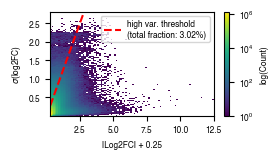

In [43]:
plt.figure(figsize=cm_to_inches((7, 4)))
plt.hist2d((abs(fc_mean_std['fc_mean'])+constant_add).values.flatten(), 
           fc_mean_std['fc_std'].values.flatten(),
           bins=100, 
           cmap='viridis',
           rasterized=True,
           norm=matplotlib.colors.LogNorm())
total_fraction = fc_mean_std['high_ratio'].sum() / len(fc_mean_std)
plt.plot([0, 10], [0, 10], color="red", linestyle="--", label=f"high var. threshold\n(total fraction: {total_fraction:.2%})")
plt.colorbar(label='log(Count)')
plt.legend(loc="upper right")
plt.xlabel(f"|Log2FC| + {constant_add}")
plt.ylabel(f"$\sigma$(log2FC)")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"fc_mean_std_2dhist.svg"), dpi=300)

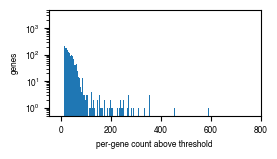

In [45]:
high_counts_gene_across = high_counts_gene.groupby('gene')["count"].sum()
plt.figure(figsize=cm_to_inches((7, 4)))
bins = np.arange(-0.5, max(high_counts_gene_across)+1.5, 1)
vals = high_counts_gene_across.value_counts().sort_index()
plt.bar(vals.index, vals.values)

#plt.axvline(x=high_counts_gene_across['7SK'], color='darkred', linestyle='--', label='7SK')
#plt.text(high_counts_gene_across['7SK']+25, 1000, '7SK', fontsize=8, color='darkred')
plt.yscale('log')
plt.xlabel("per-gene count above threshold")
plt.xlim(-50, 800)
plt.ylim(0.5, 5000)
plt.ylabel("genes")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"high_counts_gene_across.svg"), dpi=300)

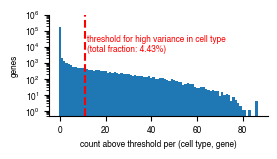

In [78]:
plt.figure(figsize=cm_to_inches((7, 4)))
# Changed bin step from 2 to 1 to ensure a separate bar for 0-valued counts
plt.hist(high_counts_gene['count'], bins=np.arange(-0.5, max(high_counts_gene['count'])+1.5, 1), bottom=1e-1)
fraction = (high_counts_gene['count'] > 11).sum() / len(high_counts_gene)
plt.text(12, 5000, f'threshold for high variance in cell type\n(total fraction: {fraction:.2%})', fontsize=6, color='red')
plt.axvline(x=11, color='red', linestyle='--', label='per cell type threshold')
plt.yscale('log')
plt.xlabel("count above threshold per (cell type, gene)")
plt.ylabel("genes")
plt.ylim(0.5, 1e6)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"high_counts_gene_per_cell.svg"), dpi=300)

In [56]:
high_counts_gene["high"] = high_counts_gene['count'] > 10
high_cross_cell_types = high_counts_gene[high_counts_gene['high']]['gene'].value_counts().reindex(high_counts_gene['gene'].unique(), fill_value=0)

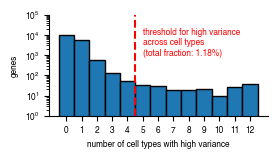

In [89]:
plt.figure(figsize=cm_to_inches((7, 4)))
# Create bins for each possible value
bins = np.arange(-0.5, high_cross_cell_types.max() + 1.5, 1)
plt.hist(high_cross_cell_types, bins=bins, edgecolor='black', bottom=1e-1)
plt.xticks(range(high_cross_cell_types.max() + 1))
plt.axvline(x=4.5, color='red', linestyle='--')
fraction = (high_cross_cell_types > 4.5).sum() / len(high_cross_cell_types)
plt.text(5, 1000, f'threshold for high variance \nacross cell types\n(total fraction: {fraction:.2%})', fontsize=6, color='red')
plt.yscale('log')
plt.ylim(1, 1e5)
plt.xlabel("number of cell types with high variance")
plt.ylabel("genes")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"high_counts_gene_across_cell_types.svg"), dpi=300)

In [85]:
questionable_genes = pd.Series(high_cross_cell_types[high_cross_cell_types >= 5].index)
questionable_genes

0      CCDC159
1      ABHD17A
2       BCAP31
3       CD2BP2
4         IER2
        ...   
186      ALDOA
187      CENPT
188       RPS9
189       EDC4
190      ZFP62
Name: gene, Length: 191, dtype: object

In [27]:
questionable_genes.to_csv('../output_tables/questionable_genes.csv', index=False)

## Check impact on lfc plots

In [ ]:
edger_df_fc_mean = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).mean()
edger_df_fc_std = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).std()

In [ ]:
cytokine = "4-1BBL"
cell_type = "B cell"
x = edger_df_log2FoldChange.loc[:, (cell_type, cytokine)]
y = edger_df_fc_mean.loc[:, (cell_type, cytokine)]

x_genes = x.dropna().index
y_genes = y.dropna().index

genes = x_genes.intersection(y_genes)
x = x.loc[genes]
y = y.loc[genes]
y_error = edger_df_fc_std.loc[genes, (cell_type, cytokine)]
questionable_filter = [g for g in questionable_genes.values if g in genes]
other_filter = [g for g in genes if g not in questionable_filter]

plt.figure(figsize=cm_to_inches((14, 12)))
plt.xlabel("all wells log2fc")
plt.ylabel("median across wells log2fc")
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.text(-1.5, 1.5, f"total questionable = {len(questionable_filter)}", fontsize=8)
plt.plot([-4, 4], [-4, 4], color="black")
plt.errorbar(x[other_filter], y[other_filter], yerr=y_error[other_filter], fmt='o', markersize=4, capsize=2, alpha=0.5, rasterized=True)
plt.errorbar(x[questionable_filter], y[questionable_filter], yerr=y_error[questionable_filter], fmt='o', markersize=4, capsize=2, alpha=0.5, color="red", rasterized=True)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"log2fc_vs_median_log2fc.{format}"), dpi=300)

# consistency filtering

In [ ]:
edger_df_padj = edger_df_padj[~edger_df_padj.index.isin(questionable_genes.values)].fillna(1)
edger_df_log2FoldChange = edger_df_log2FoldChange[~edger_df_log2FoldChange.index.isin(questionable_genes.values)].fillna(0)
edger_df_padj_wells = edger_df_padj_wells[~edger_df_padj_wells.index.isin(questionable_genes.values)].fillna(1)
edger_df_log2fc_wells = edger_df_log2fc_wells[~edger_df_log2fc_wells.index.isin(questionable_genes.values)].fillna(0)

In [ ]:
edger_df_padj_significant = edger_df_padj < 0.05
edger_df_log2fc_significant = abs(edger_df_log2FoldChange) > 0.25
edger_df_significant = edger_df_padj_significant & edger_df_log2fc_significant

In [ ]:
edger_df_padj_wells_significant = edger_df_padj_wells.fillna(1) < 0.1
edger_df_log2fc_present = abs(edger_df_log2fc_wells.fillna(0)) > 0.25

# version one: coincidence
criterion = edger_df_log2fc_present & edger_df_padj_wells_significant
criterion = criterion.groupby(level=[0,1], axis=1).sum() > 3

# version two: both criteria satisfied in enough wells
criterion_padj = edger_df_padj_wells_significant.groupby(level=[0,1], axis=1).sum() > 3
criterion_log2fc = edger_df_log2fc_present.groupby(level=[0,1], axis=1).sum() > 3
criterion = criterion_padj & criterion_log2fc

filtered_degs_well_both = criterion & edger_df_significant


filtered_degs_well_padj = (criterion_padj.groupby(level=[0,1], axis=1).sum() > 3) * edger_df_significant
filtered_degs_well_log2fc = (criterion_log2fc.groupby(level=[0,1], axis=1).sum() > 3) * edger_df_significant

In [ ]:
filtered_degs_well_both.groupby(level=[0], axis=1).sum().sum().sort_values(ascending=False)

In [ ]:
no_significant_well_both = filtered_degs_well_both.sum(axis=0)
no_significant_well_padj = filtered_degs_well_padj.sum(axis=0)
no_significant_well_log2fc = filtered_degs_well_log2fc.sum(axis=0)
no_significant_all = edger_df_significant.sum(axis=0)

In [ ]:
no_significant = pd.concat([
    no_significant_all, no_significant_well_both, no_significant_well_padj, no_significant_well_log2fc], axis=1)
no_significant.columns = ["all", "well_both", "well_padj", "well_log2fc"]

no_significant["ratio_both"] = (no_significant["well_both"]+1)/(no_significant["all"]+1)
no_significant["ratio_padj"] = (no_significant["well_padj"]+1)/(no_significant["all"]+1)
no_significant["ratio_log2fc"] = (no_significant["well_log2fc"]+1)/(no_significant["all"]+1)

In [ ]:
cell_types = no_significant.index.get_level_values(0).unique()
n_cols = 3
n_rows = (len(cell_types) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(8, 2*n_rows))
axes = axes.flatten()

for idx, cell_type in enumerate(cell_types):
    cell_data = no_significant.loc[cell_type]
    axes[idx].scatter(cell_data["all"], cell_data["well_both"], s=5, label="both")
    axes[idx].scatter(cell_data["all"], cell_data["well_log2fc"], s=5, label="log2fc only")

    axes[idx].plot(cell_data["all"], cell_data["all"], color="black", linestyle="--")
    axes[idx].set_title(f"{cell_type}")
    axes[idx].set_xlabel("All wells")
    axes[idx].set_ylabel("Consistent wells")
    axes[idx].legend(loc="upper left")

# Hide empty subplots
for idx in range(len(cell_types), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"significant_comparison_per_cell_type.png"), dpi=300)

In [ ]:
edger_df_padj[~(criterion.T.groupby(level=[0,1]).sum().T > 3)] = 1

In [ ]:
edger_df_padj.to_csv("output_tables/external_filtered_padj_by_consistency.csv")